In [1]:
# 1. 填写学号
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib
import pandas as pd

STUDENT_ID = 20244950121   # 修改为你真实学号
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]

RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")


[Conda 环境] py_course
[学号] 20244950121
[机器指纹] f547d4ea5b51bc50
[RUN_ID] 20244950121-f547d4ea5b51bc50


In [2]:
# 实验1‑1 创建int、float、bool ndarray，输出dtype、shape、ndim
arr_int = np.array([1,2,3,4])
arr_float = np.array([1.1,2.2,3.3])
arr_bool = np.array([True, False, True])

print("整数数组：")
print(f"dtype:{arr_int.dtype}, shape:{arr_int.shape}, ndim:{arr_int.ndim}")
print(arr_int)

print("\n浮点数数组：")
print(f"dtype:{arr_float.dtype}, shape:{arr_float.shape}, ndim:{arr_float.ndim}")
print(arr_float)

print("\n布尔数组：")
print(f"dtype:{arr_bool.dtype}, shape:{arr_bool.shape}, ndim:{arr_bool.ndim}")
print(arr_bool)


整数数组：
dtype:int64, shape:(4,), ndim:1
[1 2 3 4]

浮点数数组：
dtype:float64, shape:(3,), ndim:1
[1.1 2.2 3.3]

布尔数组：
dtype:bool, shape:(3,), ndim:1
[ True False  True]


### NumPy数组与Python列表区别
1. numpy数组**所有元素必须是同一个数据类型**；Python列表可以存放不同类型对象。
2. ndarray存储连续内存块，运算速度远快于list；列表存储对象指针。
3. ndarray支持批量向量化运算，不需要循环；列表遍历必须写for循环。
4. ndarray有shape、ndim、dtype描述维度与类型；原生list没有这些属性。

In [3]:
# 实验1‑2 arange创建，改变reshape形状
a = np.arange(12)
print("原始一维数组 a =", a)

a_34 = a.reshape(3,4)
print("\nreshape(3,4):")
print(a_34)

a_232 = a.reshape(2,3,2)
print("\nreshape(2,3,2):")
print(a_232)


原始一维数组 a = [ 0  1  2  3  4  5  6  7  8  9 10 11]

reshape(3,4):
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

reshape(2,3,2):
[[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]


In [4]:
# 实验1‑3 (3,4)数组索引操作
arr = np.arange(12).reshape(3,4)
print("原始数组(3,4):\n", arr)

row2 = arr[1, :]   # 取第2行（下标从0开始）
print("\n第2行：", row2, "shape", row2.shape)

col1_3 = arr[:, 0:3] # 第1‑3列
print("\n第1~3列：\n", col1_3, "shape", col1_3.shape)

gt6 = arr[arr>6]
print("\n大于6的元素：", gt6, "shape", gt6.shape)


原始数组(3,4):
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

第2行： [4 5 6 7] shape (4,)

第1~3列：
 [[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]] shape (3, 3)

大于6的元素： [ 7  8  9 10 11] shape (5,)


In [5]:
# 实验1‑4 布尔条件筛选
x = np.arange(10)
print("原始x：", x)

cond1 = (x < 2) | (x >7)
res1 = x[cond1]
print("\n小于2 或 大于7：", res1)

cond2 = (x>3) & (x<7)
res2 = x[cond2]
print("大于3 且 小于7：", res2)

# 等价写法用logical_or/logical_and
res1_2 = x[np.logical_or(x<2, x>7)]
res2_2 = x[np.logical_and(x>3, x<7)]
print("\nlogical_or结果：", res1_2)
print("logical_and结果：", res2_2)


原始x： [0 1 2 3 4 5 6 7 8 9]

小于2 或 大于7： [0 1 8 9]
大于3 且 小于7： [4 5 6]

logical_or结果： [0 1 8 9]
logical_and结果： [4 5 6]


In [6]:
# 实验1‑5 * multiply逐元素；@ matmul矩阵乘法
A = np.array([[1,2],[3,4]])
B = np.array([[5,6],[7,8]])

print("A:\n",A)
print("B:\n",B)

elem1 = A * B
elem2 = np.multiply(A,B)
mat1 = A @ B
mat2 = np.matmul(A,B)

print("\n逐元素乘法 A*B：\n", elem1)
print("np.multiply(A,B):\n", elem2)
print("\n矩阵乘法 A@B：\n", mat1)
print("np.matmul(A,B):\n", mat2)


A:
 [[1 2]
 [3 4]]
B:
 [[5 6]
 [7 8]]

逐元素乘法 A*B：
 [[ 5 12]
 [21 32]]
np.multiply(A,B):
 [[ 5 12]
 [21 32]]

矩阵乘法 A@B：
 [[19 22]
 [43 50]]
np.matmul(A,B):
 [[19 22]
 [43 50]]


* 和np.multiply：**逐元素相乘**，对应位置元素相乘，不做矩阵代数乘法。
@ 和np.matmul：数学矩阵乘法，行乘列求和，遵循矩阵相乘代数规则。

In [7]:
# 实验2‑1 生成模拟成绩，clip限制0‑100
np.random.seed(42)   #固定随机种子，保证复现
scores = np.random.normal(loc=70, scale=10, size=1000)
scores = np.clip(scores, 0, 100)

print(f"样本数:{len(scores)}")
print(f"最小值:{scores.min():.2f}")
print(f"最大值:{scores.max():.2f}")
print(f"均值:{scores.mean():.2f}")
print(f"标准差:{scores.std():.2f}")
print(f"极差:{scores.max()-scores.min():.2f}")

样本数:1000
最小值:37.59
最大值:100.00
均值:70.18
标准差:9.76
极差:62.41


In [8]:
# 实验2‑2 不放回抽样；均匀抽样 vs 加权抽样
pop = np.arange(1,11)
print("总体pop：", pop)

# 均匀不放回抽5个
sample_uniform = np.random.choice(pop, size=5, replace=False)
print("均匀不放回抽样：", sample_uniform)

# 按数值大小加权抽样
p_weights = pop / pop.sum()
sample_weighted = np.random.choice(pop, size=5, replace=False, p=p_weights)
print("按数值加权抽样：", sample_weighted)


总体pop： [ 1  2  3  4  5  6  7  8  9 10]
均匀不放回抽样： [ 4  9  2  6 10]
按数值加权抽样： [10  2  8  9  6]


In [9]:
# 实验2‑3 随机排列：不改变原数组 vs 原地打乱
arr_ori = np.arange(6)
arr_copy = arr_ori.copy()

# permutation 返回新数组，原数组不变
shuffle_new = np.random.permutation(arr_ori)
print("permutation：")
print("原数组：", arr_ori)
print("返回新数组：", shuffle_new)

# shuffle原地修改
print("\nnp.shuffle原地打乱：")
np.random.shuffle(arr_copy)
print("原地打乱之后arr_copy：", arr_copy)


permutation：
原数组： [0 1 2 3 4 5]
返回新数组： [4 0 2 1 3 5]

np.shuffle原地打乱：
原地打乱之后arr_copy： [0 5 1 4 3 2]


In [10]:
# 实验2‑4 设置nan缺失值，统计对比
scores_nan = scores.copy()
scores_nan[[9,19,29]] = np.nan   #第10、20、30个元素，下标从0开始

cnt_nan = np.sum(np.isnan(scores_nan))
mean_raw = np.mean(scores_nan)
mean_nanignore = np.nanmean(scores_nan)

print(f"缺失值数量：{cnt_nan}")
print(f"普通np.mean(含nan): {mean_raw}")
print(f"np.nanmean忽略缺失值：{mean_nanignore:.2f}")


缺失值数量：3
普通np.mean(含nan): nan
np.nanmean忽略缺失值：70.20


In [11]:
# 实验2‑5 整理成内存表格，留给实验4使用
idx_arr = np.arange(len(scores_nan))
sim_table = {"index": idx_arr, "score": scores_nan}
# 不写入磁盘，保存在内存变量sim_table

In [12]:
# 实验3‑1 scipy.linalg.solve解方程组
from scipy.linalg import solve
# 方程组
# 3x + y =9
# x +2y =8
M = np.array([[3, 1],
              [1, 2]])
b = np.array([9,8])
sol = solve(M,b)
print("方程组解 x,y =", sol)
#代入验证
x,y = sol
print(f"代入验证 3x+y={3*x+y}, x+2y={x+2*y}")


方程组解 x,y = [2. 3.]
代入验证 3x+y=9.0, x+2y=8.0


In [13]:
# 实验3‑2 scipy.optimize.root求 x²‑2=0正负根
from scipy.optimize import root

def f(x):
    return x**2 -2

res_pos = root(f, x0=1.5)  #正根初值
res_neg = root(f, x0=-1.5) #负根初值

print("正根求解成功?", res_pos.success, "根=", res_pos.x, "函数值f(x)", f(res_pos.x))
print("负根求解成功?", res_neg.success, "根=", res_neg.x, "函数值f(x)", f(res_neg.x))


正根求解成功? True 根= [1.41421356] 函数值f(x) [4.4408921e-16]
负根求解成功? True 根= [-1.41421356] 函数值f(x) [4.4408921e-16]


In [14]:
# 实验3‑3 minimize求 f(x)=x²+x+2最小值
from scipy.optimize import minimize

def fun(x):
    return x**2 + x +2

res_min = minimize(fun, x0=0)
print("极小点x：", res_min.x)
print("极小函数值：", res_min.fun)
#解析解 x=-0.5，f=1.75


极小点x： [-0.50000001]
极小函数值： 1.75


In [15]:
# 实验3‑4 t检验，固定种子
from scipy.stats import ttest_ind
np.random.seed(10)
g1 = np.random.normal(loc=0, scale=1, size=100)
g2 = np.random.normal(loc=1, scale=1, size=100)

t_stat, p_val = ttest_ind(g1,g2)
print(f"t统计量:{t_stat:.4f}, p值:{p_val:.4e}")
alpha =0.05
if p_val < alpha:
    print(f"p<{alpha},拒绝原假设，两组均值存在显著差异")
else:
    print(f"p≥{alpha},不能拒绝原假设，无充分证据说明均值不同")


t统计量:-7.1333, p值:1.8026e-11
p<0.05,拒绝原假设，两组均值存在显著差异


e:\CCConda\envs\py_course\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 39057 (\N{CJK UNIFIED IDEOGRAPH-9891}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
e:\CCConda\envs\py_course\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
e:\CCConda\envs\py_course\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 25104 (\N{CJK UNIFIED IDEOGRAPH-6210}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
e:\CCConda\envs\py_course\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 32489 (\N{CJK UNIFIED IDEOGRAPH-7EE9}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
e:\CCConda\envs\py_course\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 30452 (\N{CJK UNIFIED IDEOGRAPH-76F4}) missing from font(s) DejaV

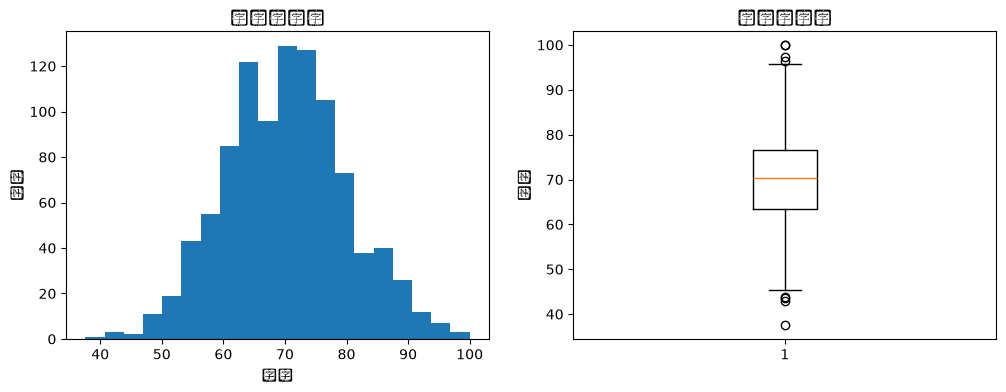

e:\CCConda\envs\py_course\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 20989 (\N{CJK UNIFIED IDEOGRAPH-51FD}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
e:\CCConda\envs\py_course\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 20687 (\N{CJK UNIFIED IDEOGRAPH-50CF}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


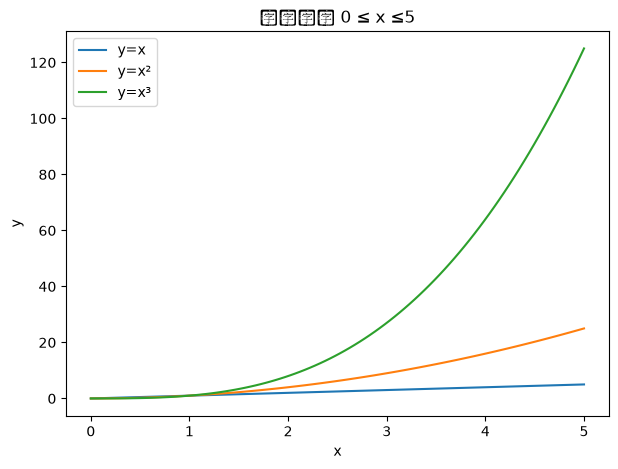

In [16]:
# 实验3‑5 matplotlib绘图：直方图、箱线图；y=x y=x² y=x³
import matplotlib.pyplot as plt

# 有效成绩（过滤nan）
scores_valid = scores[~np.isnan(scores_nan)]

plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.hist(scores_valid, bins=20)
plt.title("成绩直方图")
plt.xlabel("分数")
plt.ylabel("频数")

plt.subplot(1,2,2)
plt.boxplot(scores_valid)
plt.title("成绩箱线图")
plt.ylabel("分数")
plt.show()

# 函数曲线
x = np.linspace(0,5,100)
y1 = x
y2 = x**2
y3 = x**3
plt.figure(figsize=(7,5))
plt.plot(x,y1,label="y=x")
plt.plot(x,y2,label="y=x²")
plt.plot(x,y3,label="y=x³")
plt.legend()
plt.title("函数图像 0 ≤ x ≤5")
plt.xlabel("x")
plt.ylabel("y")
plt.show()


In [17]:
# 实验4‑1 创建DataFrame，计算总分、平均分
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}
df = pd.DataFrame(records)
df = df.set_index("Name")

# 计算总分、平均分
df["Total"] = df["Math"] + df["English"] + df["Python"]
df["Average"] = df["Total"] / 3

print("行索引：", df.index.tolist())
print("列名：", df.columns.tolist())
print("\n前3行：")
print(df.head(3))
print("\n统计信息：")
print(df.describe())


行索引： ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名： ['Group', 'Math', 'English', 'Python', 'Total', 'Average']

前3行：
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333

统计信息：
            Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000


In [18]:
# 实验4‑2 loc iloc读取Carol；筛选平均分≥80
print("loc读取Carol：")
print(df.loc["Carol"])

print("\niloc读取Carol(Carol是第2行下标=1)：")
print(df.iloc[1])

high_avg = df[df["Average"] >=80]
print("\n平均分≥80学生：")
print(high_avg)


loc读取Carol：
Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

iloc读取Carol(Carol是第2行下标=1)：
Group              A
Math              72
English           68
Python            80
Total            220
Average    73.333333
Name: Bob, dtype: object

平均分≥80学生：
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Carol     B    91       85      89    265  88.333333
Eva       A    79       92      86    257  85.666667
Frank     B    84       77      82    243  81.000000


In [19]:
# 实验4‑3 axis=0列均值；axis=1行均值
col_mean = df[["Math","English","Python"]].mean(axis=0)
row_mean = df[["Math","English","Python"]].mean(axis=1)
print("各科列均值(axis=0):\n", col_mean)
print("\n每个人行均值(axis=1):\n", row_mean)

各科列均值(axis=0):
 Math       79.833333
English    80.833333
Python     83.666667
dtype: float64

每个人行均值(axis=1):
 Name
Alice    91.000000
Bob      73.333333
Carol    88.333333
David    69.333333
Eva      85.666667
Frank    81.000000
dtype: float64


In [20]:
# 实验4‑4 apply求单科最高分；agg统计；rank排名
df["max_subject"] = df[["Math","English","Python"]].apply(max, axis=1)
print("每个人单科最高分：\n", df["max_subject"])

stat_agg = df[["Math","English","Python"]].agg(["min","mean","max"])
print("\nagg每科min mean max：\n", stat_agg)

df["math_rank"] = df["Math"].rank(ascending=False)
print("\n数学成绩排名：")
print(df[["Math","math_rank"]])

每个人单科最高分：
 Name
Alice    95
Bob      80
Carol    91
David    73
Eva      92
Frank    84
Name: max_subject, dtype: int64

agg每科min mean max：
            Math    English     Python
min   65.000000  68.000000  70.000000
mean  79.833333  80.833333  83.666667
max   91.000000  92.000000  95.000000

数学成绩排名：
       Math  math_rank
Name                  
Alice    88        2.0
Bob      72        5.0
Carol    91        1.0
David    65        6.0
Eva      79        4.0
Frank    84        3.0


In [21]:
# 实验4‑6 filter筛选组
group_filtered = df.groupby("Group").filter(lambda g: g["Python"].mean() >=80)
print("Python组平均分≥80的学生：")
print(group_filtered)

Python组平均分≥80的学生：
      Group  Math  English  Python  Total    Average  max_subject  math_rank
Name                                                                        
Alice     A    88       90      95    273  91.000000           95        2.0
Bob       A    72       68      80    220  73.333333           80        5.0
Carol     B    91       85      89    265  88.333333           91        1.0
David     B    65       73      70    208  69.333333           73        6.0
Eva       A    79       92      86    257  85.666667           92        4.0
Frank     B    84       77      82    243  81.000000           84        3.0


In [22]:
# 实验4‑7 协方差、相关系数矩阵
subj = df[["Math","English","Python"]]
cov_mat = subj.cov()
corr_mat = subj.corr()
print("协方差矩阵：\n", cov_mat)
print("\n相关系数矩阵：\n", corr_mat)

协方差矩阵：
               Math    English     Python
Math     98.166667  62.566667  74.933333
English  62.566667  93.366667  62.533333
Python   74.933333  62.533333  73.066667

相关系数矩阵：
              Math   English    Python
Math     1.000000  0.653529  0.884776
English  0.653529  1.000000  0.757105
Python   0.884776  0.757105  1.000000


### 协方差与相关系数解读
协方差符号代表变量变化方向：正数两变量同向变化；负数反向。
协方差受数据量纲影响；皮尔森相关系数归一化到[-1,1]。
系数越接近1代表强正相关；越接近‑1强负相关；接近0代表几乎无线性相关。